In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Bibliotecas cargadas correctamente")
print("Carpeta del Notebook:", Path.cwd())
print("CSV encontrados en Descargas:")
for archivo in (Path.home() / "Downloads").glob("PEC2_Raincloud*.csv"):
    print(archivo)

Bibliotecas cargadas correctamente
Carpeta del Notebook: C:\Users\sacco\anaconda_projects\59aef97a-7dec-4cc6-b99f-9102b70d1ae7
CSV encontrados en Descargas:
C:\Users\sacco\Downloads\PEC2_Raincloud_Gapminder_2023_Regiones.csv


In [2]:
# Cargar los datos de Gapminder 2023
ruta = Path.home() / "Downloads" / "PEC2_Raincloud_Gapminder_2023_Regiones.csv"

df = pd.read_csv(ruta)

# Mostrar dimensiones y primeras filas
print("Número de países:", len(df))
print("Columnas:", df.columns.tolist())

display(df.head())

Número de países: 193
Columnas: ['geo', 'name', 'anio', 'pib_per_capita', 'esperanza_vida', 'poblacion', 'region']


,geo,name,anio,pib_per_capita,esperanza_vida,poblacion,region
0,afg,Afghanistan,2023,1983.81262,68.5,41454761.0,Asia
1,alb,Albania,2023,17991.01614,79.6,2811655.0,Europe
2,dza,Algeria,2023,15159.32424,76.0,46164219.0,Africa
3,and,Andorra,2023,64631.29639,83.9,80856.0,Europe
4,ago,Angola,2023,7250.40270,64.3,36749906.0,Africa


In [3]:
# Resumen estadístico de la esperanza de vida por región
resumen = (
    df.groupby("region")["esperanza_vida"]
    .agg(
        paises="count",
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max",
        desviacion="std"
    )
    .round(2)
    .sort_values("mediana", ascending=False)
)

display(resumen)

,paises,media,mediana,minimo,maximo,desviacion
region,,,,,,
Europe,43,79.79,80.90,72.5,85.1,3.25
South America,12,75.45,76.80,69.0,80.8,3.62
North America,23,75.52,76.10,61.0,81.9,3.93
Asia,47,75.21,74.90,65.4,85.4,4.79
Oceania,14,69.38,68.30,59.0,83.9,6.81
Africa,54,65.74,64.85,55.0,76.3,5.15


Gráfico guardado en: C:\Users\sacco\Downloads\PEC2_Raincloud_Gapminder_2023.png


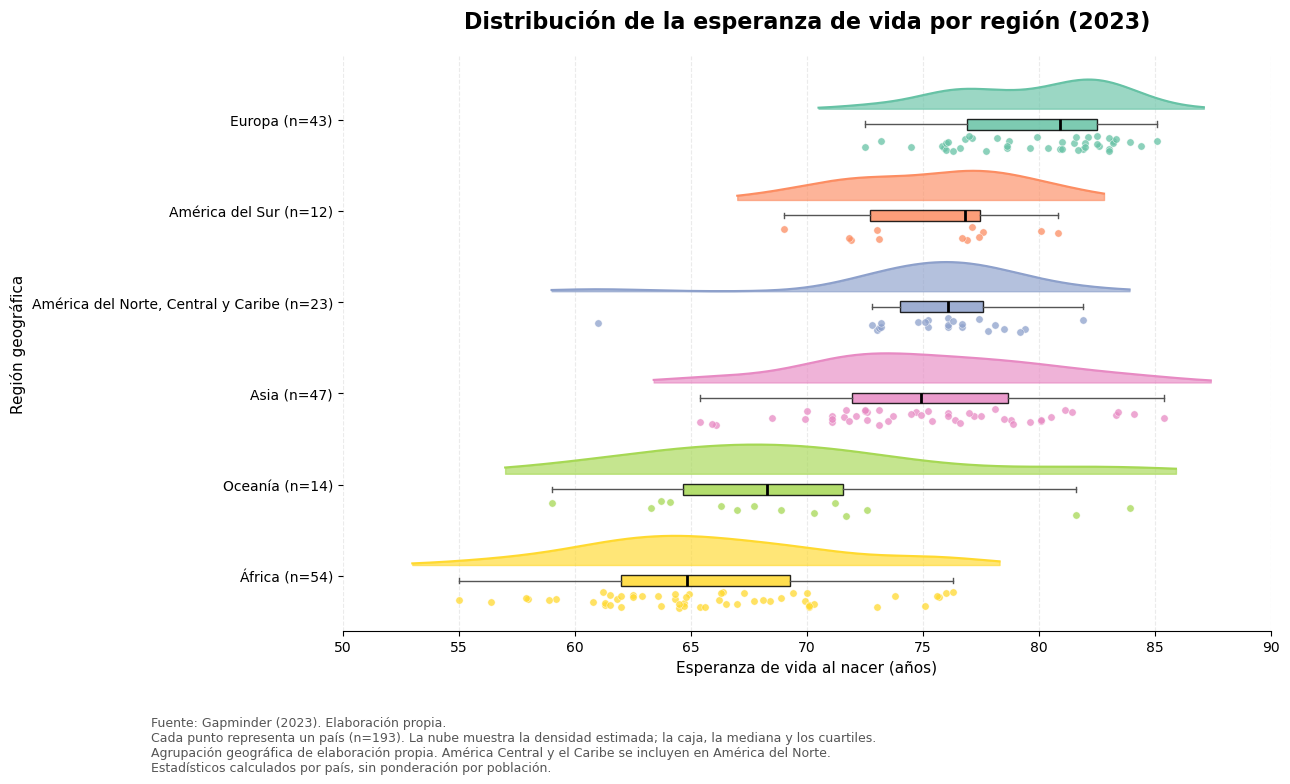

In [8]:
import numpy as np
from scipy.stats import gaussian_kde

# Ordenar regiones según su mediana
orden = resumen.index.tolist()
colores = sns.color_palette("Set2", len(orden))

fig, ax = plt.subplots(figsize=(13, 8))
rng = np.random.default_rng(42)

for i, region in enumerate(orden):

    valores = df.loc[
        df["region"] == region,
        "esperanza_vida"
    ].dropna().to_numpy()

    color = colores[i]

    # 1. Media nube de densidad, encima de cada región
    x = np.linspace(valores.min() - 2,
                    valores.max() + 2, 200)

    kde = gaussian_kde(valores, bw_method="scott")
    densidad = kde(x)

    # Normalizar altura de la nube
    densidad = densidad / densidad.max() * 0.32

    ax.fill_between(
        x, i - 0.12, i - 0.12 - densidad,
        color=color, alpha=0.65
    )

    ax.plot(
        x, i - 0.12 - densidad,
        color=color, linewidth=1.5
    )

    # 2. Boxplot
    ax.boxplot(
        valores,
        positions=[i + 0.05],
        vert=False,
        widths=0.12,
        patch_artist=True,
        showfliers=False,
        boxprops=dict(facecolor=color, alpha=0.85),
        medianprops=dict(color="black", linewidth=2),
        whiskerprops=dict(color="#555555"),
        capprops=dict(color="#555555")
    )

    # 3. Puntos individuales
    jitter = rng.uniform(0.17, 0.35, len(valores))

    ax.scatter(
        valores,
        i + jitter,
        color=color,
        alpha=0.75,
        s=28,
        edgecolor="white",
        linewidth=0.4
    )

nombres_regiones = {
    "Europe": "Europa",
    "South America": "América del Sur",
    "North America": "América del Norte, Central y Caribe",
    "Asia": "Asia",
    "Oceania": "Oceanía",
    "Africa": "África"
}

etiquetas = [
    f"{nombres_regiones[r]} (n={len(df[df['region'] == r])})"
    for r in orden
]

ax.set_yticks(range(len(orden)))
ax.set_yticklabels(etiquetas)
ax.invert_yaxis()

ax.set_xlabel("Esperanza de vida al nacer (años)", fontsize=11)
ax.set_ylabel("Región geográfica", fontsize=11)

ax.set_title(
    "Distribución de la esperanza de vida por región (2023)",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlim(50, 90)
ax.set_ylim(len(orden) - 0.4, -0.7)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

sns.despine(ax=ax, left=True)
# Fuente y explicación metodológica
fig.text(
    0.12, 0.025,
    "Fuente: Gapminder (2023). Elaboración propia.\n"
    "Cada punto representa un país (n=193). "
    "La nube muestra la densidad estimada; "
    "la caja, la mediana y los cuartiles.\n"
    "Agrupación geográfica de elaboración propia. "
    "América Central y el Caribe se incluyen en América del Norte.\n"
    "Estadísticos calculados por país, sin ponderación por población.",
    fontsize=9,
    color="#555555",
    ha="left",
    va="bottom"
)

# Reservar espacio para las notas
plt.tight_layout(rect=[0, 0.13, 1, 1])

# Guardar gráfico en alta resolución
archivo_salida = Path.home() / "Downloads" / "PEC2_Raincloud_Gapminder_2023.png"

fig.savefig(
    archivo_salida,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Gráfico guardado en:", archivo_salida)

plt.show()

In [9]:
# Definir los tres conjuntos de países
df["vida_alta"] = df["esperanza_vida"] >= 80
df["pib_alto"] = df["pib_per_capita"] >= 30000
df["poblacion_alta"] = df["poblacion"] >= 50000000

# Contar los países que cumplen cada criterio
print("Esperanza de vida >= 80 años:",
      df["vida_alta"].sum())

print("PIB per cápita >= 30.000:",
      df["pib_alto"].sum())

print("Población >= 50 millones:",
      df["poblacion_alta"].sum())

print("Países que cumplen los tres criterios:",
      (df["vida_alta"] &
       df["pib_alto"] &
       df["poblacion_alta"]).sum())

Esperanza de vida >= 80 años: 37
PIB per cápita >= 30.000: 59
Población >= 50 millones: 30
Países que cumplen los tres criterios: 6


In [10]:
try:
    import upsetplot
    print("La biblioteca upsetplot está instalada.")
except ImportError:
    print("La biblioteca upsetplot NO está instalada.")

La biblioteca upsetplot NO está instalada.


In [11]:
%pip install upsetplot

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for upsetplot: filename=upsetplot-0.9.0-py3-none-any.whl size=24912 sha256=0f8163f2cfbbd4db77583a09c8b5e453d3caafd6fd7719e2d20a5b0b919d8ca1
  Stored in directory: c:\users\sacco\appdata\local\pip\cache\wheels\25\f7\e8\cf1a20f6721631b3607d04dfd5c31889cf5a512177fa2a0564
Successfully built upsetplot
Note: you may need to restart the kernel to use updated packages.


Datos recuperados: 193 países


C:\Users\sacco\anaconda3\Lib\site-packages\upsetplot\plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
C:\Users\sacco\anaconda3\Lib\site-packages\upsetplot\plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For ex

Gráfico guardado en: C:\Users\sacco\Downloads\PEC2_UpSet_Gapminder_2023.png


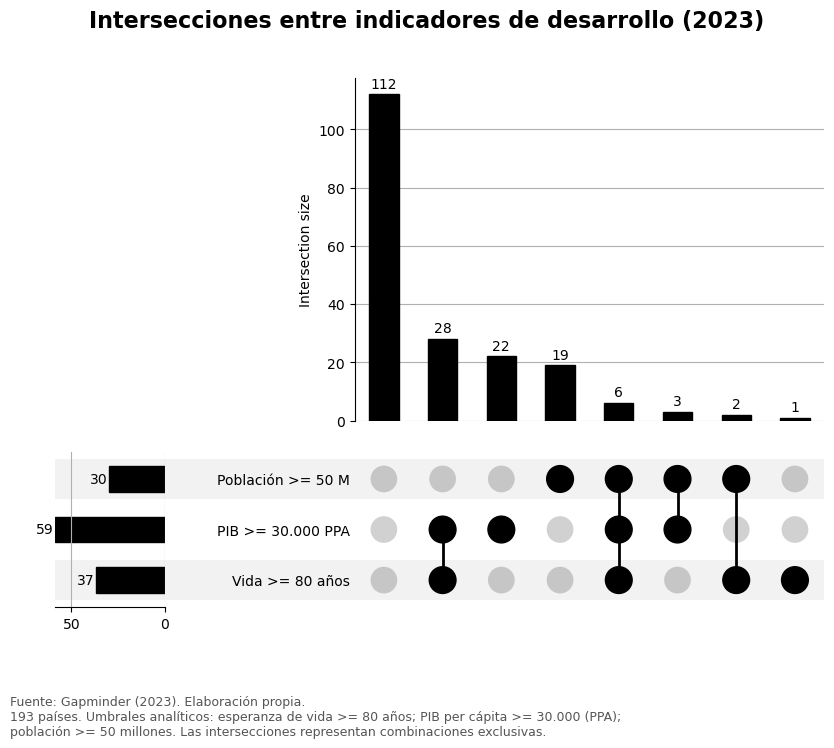

In [7]:
import pandas as pd
from pathlib import Path

ruta = Path.home() / "Downloads" / "PEC2_Raincloud_Gapminder_2023_Regiones.csv"

df = pd.read_csv(ruta)

df["vida_alta"] = df["esperanza_vida"] >= 80
df["pib_alto"] = df["pib_per_capita"] >= 30000
df["poblacion_alta"] = df["poblacion"] >= 50000000

print("Datos recuperados:", len(df), "países")
from upsetplot import UpSet, from_indicators
import matplotlib.pyplot as plt

# Preparar los tres conjuntos
conjuntos = df[
    ["vida_alta", "pib_alto", "poblacion_alta"]
].copy()

# Asignar nombres descriptivos
conjuntos.columns = [
    "Vida >= 80 años",
    "PIB >= 30.000 PPA",
    "Población >= 50 M"
]

# Crear estructura de intersecciones
datos_upset = from_indicators(conjuntos)

# Construir el UpSet Plot
upset = UpSet(
    datos_upset,
    subset_size="count",
    show_counts=True,
    sort_by="cardinality",
    sort_categories_by=None,
    element_size=55
)

fig = plt.figure(figsize=(9, 6))

upset.plot(fig=fig)

fig.suptitle(
    "Intersecciones entre indicadores de desarrollo (2023)",
    fontsize=16,
    fontweight="bold"
)

# Fuente y nota metodológica
fig.text(
    0.08, -0.08,
    "Fuente: Gapminder (2023). Elaboración propia.\n"
    "193 países. Umbrales analíticos: esperanza de vida >= 80 años; "
    "PIB per cápita >= 30.000 (PPA);\n"
    "población >= 50 millones. "
    "Las intersecciones representan combinaciones exclusivas.",
    fontsize=9,
    color="#555555",
    ha="left",
    va="bottom"
)

# Guardar gráfico en alta resolución
archivo_salida = (
    Path.home() / "Downloads" /
    "PEC2_UpSet_Gapminder_2023.png"
)

fig.savefig(
    archivo_salida,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Gráfico guardado en:", archivo_salida)

plt.show()